In [1]:
import numpy as np
import matplotlib.pyplot as plt
import astrotools.constants as c
from astrotools.disk import structure
from astrotools.disk import viscous
from scipy.optimize import curve_fit
import pandas as pd

# HW 4

## Problem 1: Build the Module

In [2]:
from astrotools.nbody import drag as d

initial_state = d.initial_state(1.0, 0.1, 0.41)

In [3]:
derivs = d.hill_drag_derivs(0.0, initial_state , 0.1, 0.41)
vx, vy, ax, ay = derivs
print("ax = %.3g" %np.abs(ax))
print("ay + 1.5*vx = %.3g" %np.abs(ay + 1.5*vx))

ax = 0.00172
ay + 1.5*vx = 0.0206


In [4]:
from astrotools.nbody import integrators as i

st = 0.1
dv = 0.41
r_cap = 0.05


func = lambda t, y: d.hill_drag_derivs(t, y, 0.1, 0.41)
capture_1 = d.encounter(i.rk4_step, func, initial_state, r_cap)

initial_state2 = d.initial_state(2.0, 0.1, 0.41)
capture_2 = d.encounter(i.rk4_step, func, initial_state2, r_cap)

In [5]:
print("A pebble starting at x = 1.0 was captured: %s " %capture_1[0])
print("A pebble starting at x = 2.0 was captured: %s " %capture_2[0])

A pebble starting at x = 1.0 was captured: True 
A pebble starting at x = 2.0 was captured: False 


## Problem 2: Capturing Pebbles

### Part (a)

In [6]:
from astrotools import constants as c
from astrotools.disk import structure as s

dist = 5.2 * c.AU
dv = 0.41
st = 0.1
r_cap = 0.05
dx_0 = 0.05

x0_arr = np.arange(-6, 6, dx_0)

M_dot = 1.39 sigma * omega_k * Rh^2
Analytic M_dot = 1.34 sigma * omega_k * Rh^2
Percent difference = 3.03 %


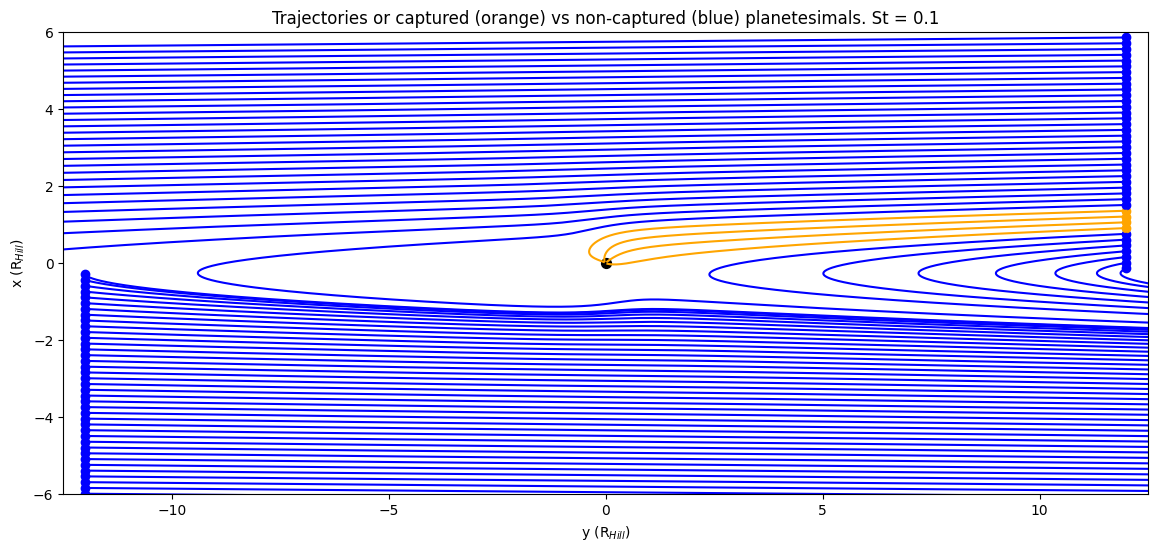

In [7]:
fig, ax = plt.subplots(figsize = [14,6])
ax.scatter(0,0, s= 50, color = 'black')
ax.set_ylim(-6,6)
ax.set_xlim(-12.5,12.5)
ax.set_xlabel("y (R$_{Hill}$)")
ax.set_ylabel("x (R$_{Hill}$)")
ax.set_title("Trajectories or captured (orange) vs non-captured (blue) planetesimals. St = 0.1")

captured = []
for x0 in range(len(x0_arr)):
    y0 = d.initial_state(x0_arr[x0], st, dv)
    func = lambda t, y: d.hill_drag_derivs(t, y, st, dv)
    result = d.encounter(i.rk4_step, func, y0, r_cap)
    captured.append(result[0])
    if result[0] == True:
        x = result[2][:, 0] 
        y = result[2][:, 1] 
        if x0 % 3 == 0:
            ax.plot(y,x, color = 'orange')
            ax.scatter(y[0],x[0], color = 'orange')
    else:
        x = result[2][:, 0] 
        y = result[2][:, 1] 
        if x0 % 3 == 0:
            ax.plot(y,x, color = 'blue')
            ax.scatter(y[0],x[0], color = 'blue')

m_dot = 0
for x0 in x0_arr[captured]:
    y0 = d.initial_state(x0, st, dv)
    vy0 = y0[3]
    m_dot += (abs(vy0) * dx_0)

analytic_mdot = 3 * (3 * st)**(2/3)
percent_diff = (abs(m_dot - analytic_mdot) / analytic_mdot) * 100

print("M_dot = %.3g sigma * omega_k * Rh^2" %m_dot)
print("Analytic M_dot = %.3g sigma * omega_k * Rh^2" %analytic_mdot)
print("Percent difference = %.3g %%" %percent_diff)

### Part (b)

M_dot = 3.12 sigma * omega_k * Rh^2
Analytic M_dot = 6.24 sigma * omega_k * Rh^2
Percent difference = 49.9 %


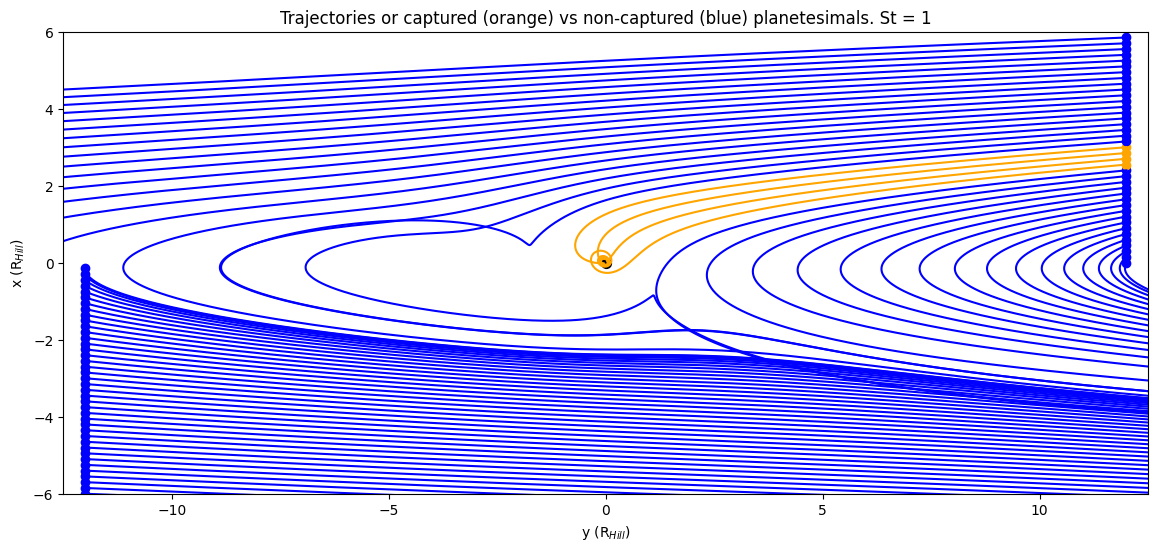

In [8]:
fig, ax = plt.subplots(figsize = [14,6])
ax.scatter(0,0, s= 50, color = 'black')
ax.set_ylim(-6,6)
ax.set_xlim(-12.5,12.5)
#ax.axhspan(2.5, 3.3, color = 'orange', zorder = 0, alpha = 0.5)
ax.set_xlabel("y (R$_{Hill}$)")
ax.set_ylabel("x (R$_{Hill}$)")
ax.set_title("Trajectories or captured (orange) vs non-captured (blue) planetesimals. St = 1")

st = 1.0
captured = []
for x0 in range(len(x0_arr)):
    y0 = d.initial_state(x0_arr[x0], st, dv)
    func = lambda t, y: d.hill_drag_derivs(t, y, st, dv)
    result = d.encounter(i.rk4_step, func, y0, r_cap)
    captured.append(result[0])
    if result[0] == True:
        x = result[2][:, 0] 
        y = result[2][:, 1] 
        if x0 % 3 == 0:
            ax.plot(y,x, color = 'orange')
            ax.scatter(y[0],x[0], color = 'orange')
    else:
        x = result[2][:, 0] 
        y = result[2][:, 1] 
        if x0 % 3 == 0:
            ax.plot(y,x, color = 'blue')
            ax.scatter(y[0],x[0], color = 'blue')

m_dot = 0
for x0 in x0_arr[captured]:
    y0 = d.initial_state(x0, st, dv)
    vy0 = y0[3]
    m_dot += (abs(vy0) * dx_0)

analytic_mdot = 3 * (3 * st)**(2/3)
percent_diff = (abs(m_dot - analytic_mdot) / analytic_mdot) * 100

print("M_dot = %.3g sigma * omega_k * Rh^2" %m_dot)
print("Analytic M_dot = %.3g sigma * omega_k * Rh^2" %analytic_mdot)
print("Percent difference = %.3g %%" %percent_diff)

#### The analytic solution applies to particles in the shear regime, where the keplerian shear dominates over the headwind to alter the radial velocity of the accreting particle. This condition does not apply to this model, where we have a St = 1, and in this regime the change in velocity due to the headwind is at a maximum, and dominates over the keplerian shear.

### Part (c)

M_dot = 1.39 sigma * omega_k * Rh^2
Analytic M_dot = 1.34 sigma * omega_k * Rh^2
Percent difference = 3.03 %


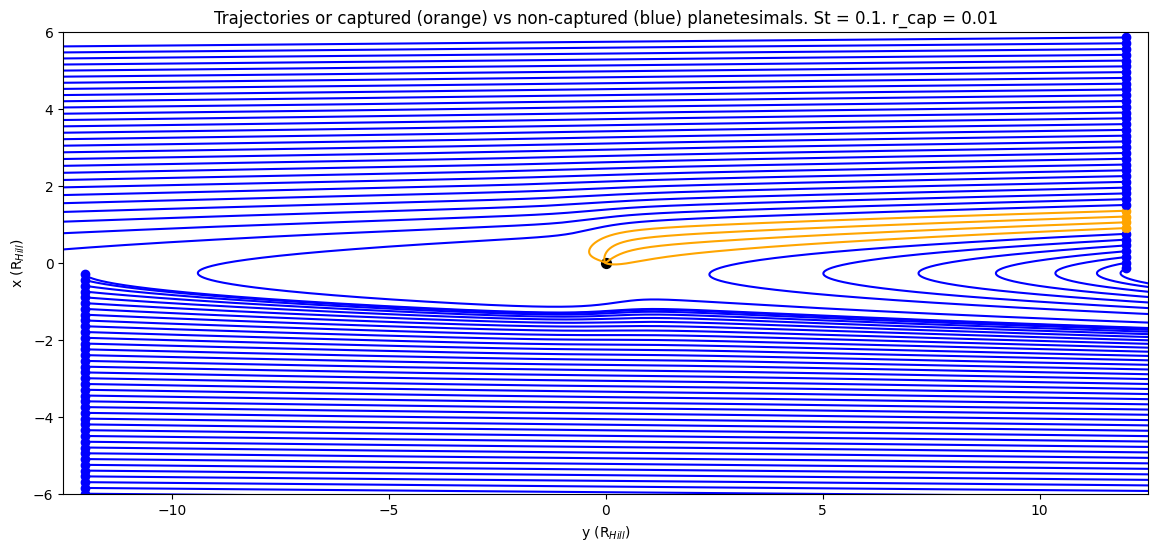

In [9]:
dist = 5.2 * c.AU
dv = 0.41
st = 0.1
r_cap = 0.01
dx_0 = 0.05

x0_arr = np.arange(-6, 6, dx_0)

fig, ax = plt.subplots(figsize = [14,6])
ax.scatter(0,0, s= 50, color = 'black')
ax.set_ylim(-6,6)
ax.set_xlim(-12.5,12.5)
ax.set_xlabel("y (R$_{Hill}$)")
ax.set_ylabel("x (R$_{Hill}$)")
ax.set_title("Trajectories or captured (orange) vs non-captured (blue) planetesimals. St = 0.1. r_cap = 0.01")

captured = []
for x0 in range(len(x0_arr)):
    y0 = d.initial_state(x0_arr[x0], st, dv)
    func = lambda t, y: d.hill_drag_derivs(t, y, st, dv)
    result = d.encounter(i.rk4_step, func, y0, r_cap)
    captured.append(result[0])
    if result[0] == True:
        x = result[2][:, 0] 
        y = result[2][:, 1] 
        if x0 % 3 == 0:
            ax.plot(y,x, color = 'orange')
            ax.scatter(y[0],x[0], color = 'orange')
    else:
        x = result[2][:, 0] 
        y = result[2][:, 1] 
        if x0 % 3 == 0:
            ax.plot(y,x, color = 'blue')
            ax.scatter(y[0],x[0], color = 'blue')

m_dot = 0
for x0 in x0_arr[captured]:
    y0 = d.initial_state(x0, st, dv)
    vy0 = y0[3]
    m_dot += (abs(vy0) * dx_0)

analytic_mdot = 3 * (3 * st)**(2/3)
percent_diff = (abs(m_dot - analytic_mdot) / analytic_mdot) * 100

print("M_dot = %.3g sigma * omega_k * Rh^2" %m_dot)
print("Analytic M_dot = %.3g sigma * omega_k * Rh^2" %analytic_mdot)
print("Percent difference = %.3g %%" %percent_diff)

M_dot = 6.47 sigma * omega_k * Rh^2
Analytic M_dot = 6.24e+04 sigma * omega_k * Rh^2
Percent difference = 100 %


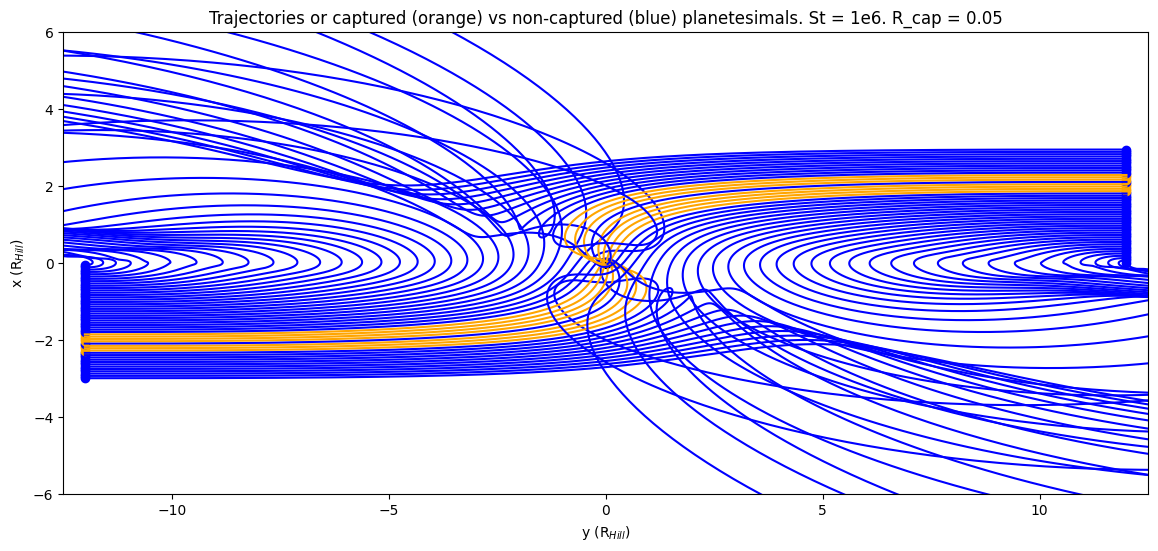

In [10]:
fig, ax = plt.subplots(figsize = [14,6])
ax.scatter(0,0, s= 50, color = 'black')
ax.set_ylim(-6,6)
ax.set_xlim(-12.5,12.5)
ax.set_xlabel("y (R$_{Hill}$)")
ax.set_ylabel("x (R$_{Hill}$)")
ax.set_title("Trajectories or captured (orange) vs non-captured (blue) planetesimals. St = 1e6. R_cap = 0.05")

x0_arr = np.arange(-3, 3, 0.02)
r_cap, st, dv = 0.05, 1e6, 0.0
captured = []
for x0 in range(len(x0_arr)):
    y0 = d.initial_state(x0_arr[x0], st, dv)
    func = lambda t, y: d.hill_drag_derivs(t, y, st, dv)
    result = d.encounter(i.rk4_step, func, y0, r_cap)
    captured.append(result[0])
    if result[0] == True:
        x = result[2][:, 0] 
        y = result[2][:, 1] 
        if x0 % 3 == 0:
            ax.plot(y,x, color = 'orange')
            ax.scatter(y[0],x[0], color = 'orange')
    else:
        x = result[2][:, 0] 
        y = result[2][:, 1] 
        if x0 % 3 == 0:
            ax.plot(y,x, color = 'blue')
            ax.scatter(y[0],x[0], color = 'blue')

m_dot = 0
for x0 in x0_arr[captured]:
    y0 = d.initial_state(x0, st, dv)
    vy0 = y0[3]
    m_dot += (abs(vy0) * dx_0)

analytic_mdot = 3 * (3 * st)**(2/3)
percent_diff = (abs(m_dot - analytic_mdot) / analytic_mdot) * 100

print("M_dot = %.3g sigma * omega_k * Rh^2" %m_dot)
print("Analytic M_dot = %.3g sigma * omega_k * Rh^2" %analytic_mdot)
print("Percent difference = %.3g %%" %percent_diff)

M_dot = 2.79 sigma * omega_k * Rh^2
Analytic M_dot = 6.24e+04 sigma * omega_k * Rh^2
Percent difference = 100 %


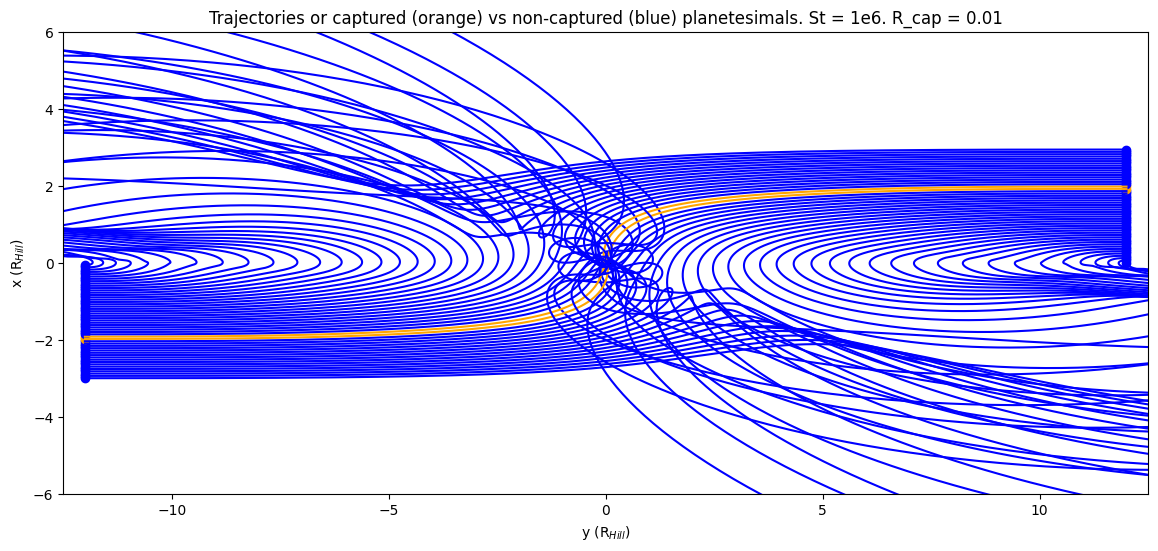

In [11]:
fig, ax = plt.subplots(figsize = [14,6])
ax.scatter(0,0, s= 50, color = 'black')
ax.set_ylim(-6,6)
ax.set_xlim(-12.5,12.5)
ax.set_xlabel("y (R$_{Hill}$)")
ax.set_ylabel("x (R$_{Hill}$)")
ax.set_title("Trajectories or captured (orange) vs non-captured (blue) planetesimals. St = 1e6. R_cap = 0.01")

x0_arr = np.arange(-3, 3, 0.02)
r_cap, st, dv = 0.01, 1e6, 0.0
captured = []
for x0 in range(len(x0_arr)):
    y0 = d.initial_state(x0_arr[x0], st, dv)
    func = lambda t, y: d.hill_drag_derivs(t, y, st, dv)
    result = d.encounter(i.rk4_step, func, y0, r_cap)
    captured.append(result[0])
    if result[0] == True:
        x = result[2][:, 0] 
        y = result[2][:, 1] 
        if x0 % 3 == 0:
            ax.plot(y,x, color = 'orange')
            ax.scatter(y[0],x[0], color = 'orange')
    else:
        x = result[2][:, 0] 
        y = result[2][:, 1] 
        if x0 % 3 == 0:
            ax.plot(y,x, color = 'blue')
            ax.scatter(y[0],x[0], color = 'blue')

m_dot = 0
for x0 in x0_arr[captured]:
    y0 = d.initial_state(x0, st, dv)
    vy0 = y0[3]
    m_dot += (abs(vy0) * dx_0)

analytic_mdot = 3 * (3 * st)**(2/3)
percent_diff = (abs(m_dot - analytic_mdot) / analytic_mdot) * 100

print("M_dot = %.3g sigma * omega_k * Rh^2" %m_dot)
print("Analytic M_dot = %.3g sigma * omega_k * Rh^2" %analytic_mdot)
print("Percent difference = %.3g %%" %percent_diff)

#### I'm not sure why the analytical expression for accretion in the shear regime doesn't seem to apply for St = 1e6, since the headwind is negligible, and the keplerian shear should dominate for these planetesimals...

#### For the shear regime, the encounter time doesn't depend on the impact parameter, so I'm guessing that's why changing the capture radius doesn't impact the accretion rate for St = 0.1. However, I'm still not convinced that the shear regime applies to the St = 0.1 case, and that it doesn't apply to the St = 1e6 case.

## Problem 3: Holding Trojans

### Part (a)

In [12]:
import rebound as re

In [13]:
sim = re.Simulation()
sim.units = ("s", "AU", "Msun")

#Jupiter
mu = 9.54e-4
a_J = 5.20
omega_J = s.keplerian_omega(a_J * c.AU)
x_J = (1 - mu) * a_J
vy_J = (1 - mu) * a_J * omega_J

#Sun
m_S = 1 - mu
x_S = -mu * a_J
vy_S = -mu * a_J * omega_J

#test particle
r_L4  = np.array([a_J * (0.5 - mu), np.sqrt(3) / 2 * a_J])
r_hat = r_L4 / np.linalg.norm(r_L4)
x_t, y_t = r_L4 + 1e-3 * a_J * r_hat
vx, vy = -omega_J * y_t, omega_J * x_t

period = (2*np.pi / omega_J)
lib_period = period / np.sqrt(27 * mu / 4)


sim.add(m=m_S, x = x_S, vy = vy_S)  # Sun
sim.add(m=mu, x = x_J, vy = vy_J)      # Jupiter
sim.add(m=0.0, x=x_t, y=y_t, vx=vx, vy=vy) # Test

sim.move_to_com()
sim.integrator = "ias15"
sim.N_active = 2 

In [14]:
times = np.linspace(0, 300 * period, 3000)               # seconds
xy = np.zeros((len(times), 3, 2))
E0 = sim.energy()

for k, t in enumerate(times):
    sim.integrate(t)
    for i, p in enumerate(sim.particles):
        xy[k, i] = p.x, p.y

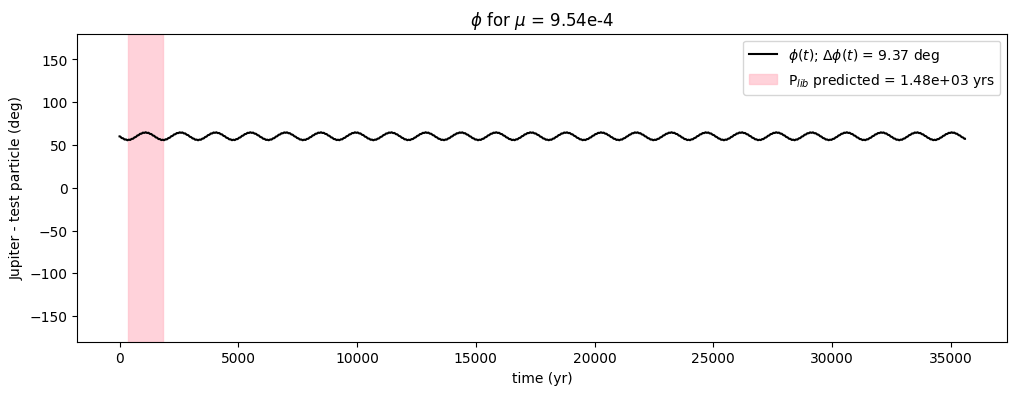

In [15]:
def angle_from_star(xy, i, j):
    """Angle of body j relative to body i as seen from body 0, in degrees."""
    d_i = xy[:, i] - xy[:, 0]
    d_j = xy[:, j] - xy[:, 0]
    ang = np.arctan2(d_j[:, 1], d_j[:, 0]) - np.arctan2(d_i[:, 1], d_i[:, 0])
    return np.degrees((ang + np.pi) % (2 * np.pi) - np.pi)

phi = angle_from_star(xy, 1, 2)

times_yr = times/360/24/365
lib_period_yr = lib_period/360/24/365

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(times_yr, phi, color = 'black', label = "$\phi(t)$; $\Delta\phi(t)$ = %.3g deg" %(np.max(phi) - np.min(phi)))
ax.axvspan(times_yr[30], times_yr[30] + lib_period_yr, color = 'pink', alpha = 0.7, label = "P$_{lib}$ predicted = %.3g yrs" %lib_period_yr)
#lib_period_meas = (times_yr[np.argmax(phi)] - times_yr[np.argmin(phi)])
#ax.axvspan(times_yr[30], times_yr[30] + meas_lib_period, color = 'blue', alpha = 0.2, label = "P$_{lib}$ measured = %.3g yrs" %meas_lib_period)
ax.set(xlabel="time (yr)", ylabel="Jupiter - test particle (deg)", ylim=(-180, 180))
ax.set_title("$\phi$ for $\mu$ = 9.54e-4")
ax.legend()
plt.show()

#### Not quite sure of the best way to measure the libration period, so I'm gonna do it by eye:

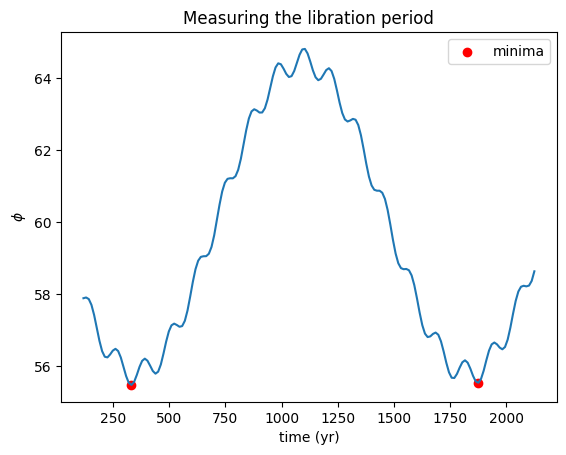

In [16]:
plt.plot(times_yr[10:180], phi[10:180])
plt.scatter(times_yr[90:180][np.argmin(phi[90:180])], phi[90:180][np.argmin(phi[90:180])], color = 'red', label = 'minima')
plt.scatter(times_yr[10:90][np.argmin(phi[10:90])], phi[10:90][np.argmin(phi[10:90])], color = 'red')
plt.title("Measuring the libration period")
plt.xlabel("time (yr)")
plt.ylabel("$\phi$")
plt.legend()

In [17]:
meas_lib_period = times_yr[90:180][np.argmin(phi[90:180])] - times_yr[10:90][np.argmin(phi[10:90])]

In [18]:
print("The measured libration period is: %.3g yrs" %meas_lib_period)
print("The predicted libration period is: %.3g yrs" %lib_period_yr)

The measured libration period is: 1.54e+03 yrs
The predicted libration period is: 1.48e+03 yrs


### Part (b)

In [19]:
sim2 = re.Simulation()
sim2.units = ("s", "AU", "Msun")

#Jupiter
mu2 = 0.03
a_J = 5.20
omega_J = s.keplerian_omega(a_J * c.AU)
x_J = (1 - mu2) * a_J
vy_J = (1 - mu2) * a_J * omega_J

#Sun
m_S = 1 - mu2
x_S = -mu2 * a_J
vy_S = -mu2 * a_J * omega_J

#test particle
r_L4  = np.array([a_J * (0.5 - mu2), np.sqrt(3) / 2 * a_J])
r_hat = r_L4 / np.linalg.norm(r_L4)
x_t, y_t = r_L4 + 1e-3 * a_J * r_hat
vx, vy = -omega_J * y_t, omega_J * x_t

period = (2*np.pi / omega_J)
lib_period = period / np.sqrt(27 * mu2 / 4)


sim2.add(m=m_S, x = x_S, vy = vy_S)  # Sun
sim2.add(m=mu2, x = x_J, vy = vy_J)      # Jupiter
sim2.add(m=0.0, x=x_t, y=y_t, vx=vx, vy=vy) # Test

sim2.move_to_com()
sim2.integrator = "ias15"
sim2.N_active = 2 

In [20]:
times = np.linspace(0, 300 * period, 3000)               # seconds
xy = np.zeros((len(times), 3, 2))
E0 = sim.energy()

for k, t in enumerate(times):
    sim2.integrate(t)
    for i, p in enumerate(sim2.particles):
        xy[k, i] = p.x, p.y

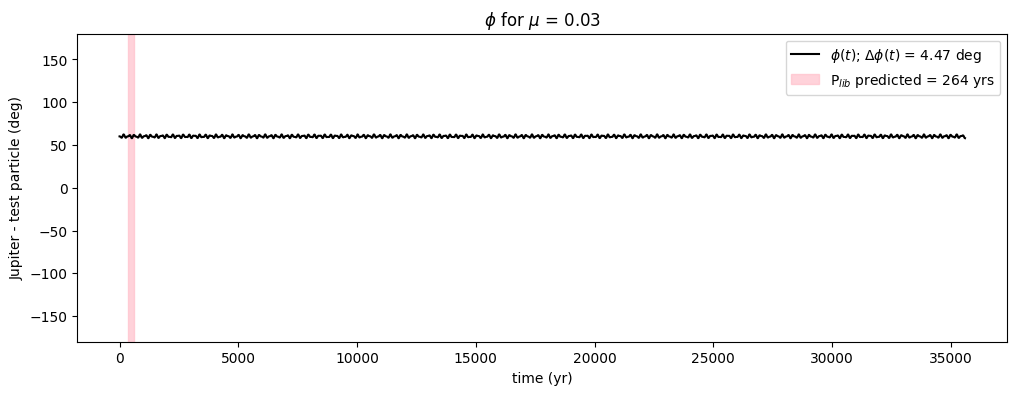

In [21]:
def angle_from_star(xy, i, j):
    """Angle of body j relative to body i as seen from body 0, in degrees."""
    d_i = xy[:, i] - xy[:, 0]
    d_j = xy[:, j] - xy[:, 0]
    ang = np.arctan2(d_j[:, 1], d_j[:, 0]) - np.arctan2(d_i[:, 1], d_i[:, 0])
    return np.degrees((ang + np.pi) % (2 * np.pi) - np.pi)

phi = angle_from_star(xy, 1, 2)

times_yr = times/360/24/365
lib_period_yr = lib_period/360/24/365

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(times_yr, phi, color = 'black', label = "$\phi(t)$; $\Delta\phi(t)$ = %.3g deg" %(np.max(phi) - np.min(phi)))
ax.axvspan(times_yr[30], times_yr[30] + lib_period_yr, color = 'pink', alpha = 0.7, label = "P$_{lib}$ predicted = %.3g yrs" %lib_period_yr)
lib_period_meas = (times_yr[np.argmax(phi)] - times_yr[np.argmin(phi)])
#ax.axvspan(times_yr[30], times_yr[30] + meas_lib_period, color = 'blue', alpha = 0.2, label = "P$_{lib}$ measured = %.3g yrs" %meas_lib_period)
ax.set(xlabel="time (yr)", ylabel="Jupiter - test particle (deg)", ylim=(-180, 180))
ax.set_title("$\phi$ for $\mu$ = 0.03")
ax.legend()
plt.show()

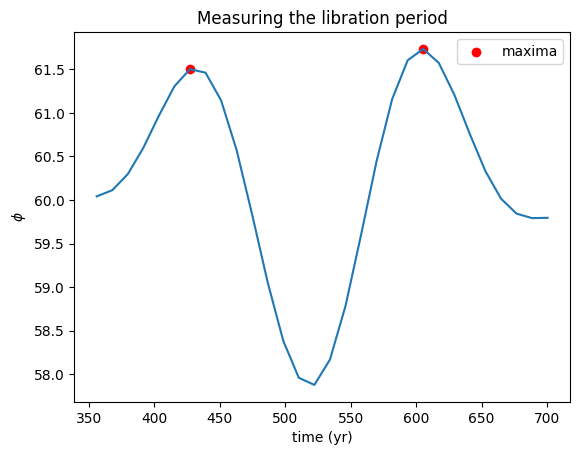

In [22]:
plt.plot(times_yr[30:60], phi[30:60])
plt.scatter(times_yr[30:45][np.argmax(phi[30:45])], phi[30:45][np.argmax(phi[30:45])], color = 'red', label = 'maxima')
plt.scatter(times_yr[45:60][np.argmax(phi[45:60])], phi[45:60][np.argmax(phi[45:60])], color = 'red')
plt.title("Measuring the libration period")
plt.xlabel("time (yr)")
plt.ylabel("$\phi$")
plt.legend()

In [23]:
meas_lib_period = times_yr[45:60][np.argmax(phi[45:60])] - times_yr[30:45][np.argmax(phi[30:45])]

In [24]:
print("The measured libration period is: %.3g yrs" %meas_lib_period)
print("The predicted libration period is: %.3g yrs" %lib_period_yr)

The measured libration period is: 178 yrs
The predicted libration period is: 264 yrs


In [25]:
sim3 = re.Simulation()
sim3.units = ("s", "AU", "Msun")

#Jupiter
mu3 = 0.05
a_J = 5.20
omega_J = s.keplerian_omega(a_J * c.AU)
x_J = (1 - mu3) * a_J
vy_J = (1 - mu3) * a_J * omega_J

#Sun
m_S = 1 - mu3
x_S = -mu3 * a_J
vy_S = -mu3 * a_J * omega_J

#test particle
r_L4  = np.array([a_J * (0.5 - mu3), np.sqrt(3) / 2 * a_J])
r_hat = r_L4 / np.linalg.norm(r_L4)
x_t, y_t = r_L4 + 1e-3 * a_J * r_hat
vx, vy = -omega_J * y_t, omega_J * x_t

period = (2*np.pi / omega_J)
lib_period = period / np.sqrt(27 * mu3 / 4)


sim3.add(m=m_S, x = x_S, vy = vy_S)  # Sun
sim3.add(m=mu3, x = x_J, vy = vy_J)      # Jupiter
sim3.add(m=0.0, x=x_t, y=y_t, vx=vx, vy=vy) # Test

sim3.move_to_com()
sim3.integrator = "ias15"
sim3.N_active = 2 

In [26]:
times = np.linspace(0, 300 * period, 3000)               # seconds
xy = np.zeros((len(times), 3, 2))
E0 = sim.energy()

for k, t in enumerate(times):
    sim3.integrate(t)
    for i, p in enumerate(sim3.particles):
        xy[k, i] = p.x, p.y

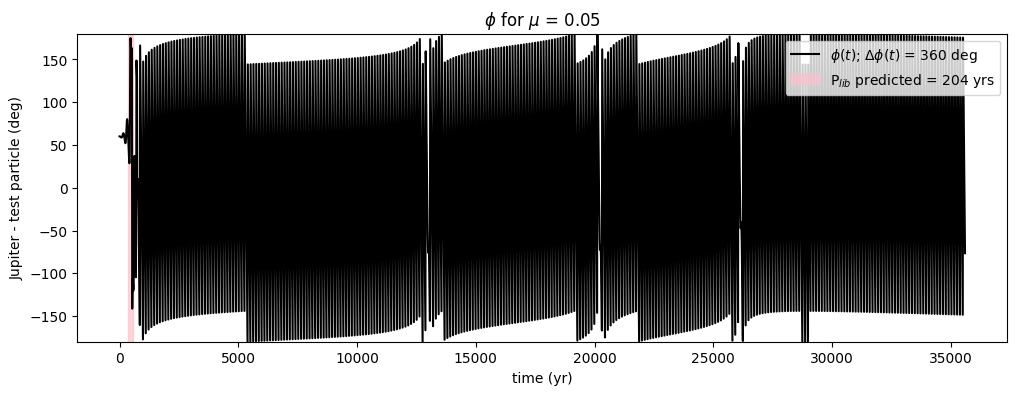

In [28]:
def angle_from_star(xy, i, j):
    """Angle of body j relative to body i as seen from body 0, in degrees."""
    d_i = xy[:, i] - xy[:, 0]
    d_j = xy[:, j] - xy[:, 0]
    ang = np.arctan2(d_j[:, 1], d_j[:, 0]) - np.arctan2(d_i[:, 1], d_i[:, 0])
    return np.degrees((ang + np.pi) % (2 * np.pi) - np.pi)

phi = angle_from_star(xy, 1, 2)

times_yr = times/360/24/365
lib_period_yr = lib_period/360/24/365

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(times_yr, phi, color = 'black', label = "$\phi(t)$; $\Delta\phi(t)$ = %.3g deg" %(np.max(phi) - np.min(phi)))
ax.axvspan(times_yr[30], times_yr[30] + lib_period_yr, color = 'pink', alpha = 0.7, label = "P$_{lib}$ predicted = %.3g yrs" %lib_period_yr)
ax.set(xlabel="time (yr)", ylabel="Jupiter - test particle (deg)", ylim=(-180, 180))
ax.set_title("$\phi$ for $\mu$ = 0.05")
ax.legend()
plt.show()

#### The particle with $\mu = 0.03$ is able to stay near $L_{4}$. 
#### This is consistent with the stability criteron, because for $\mu = 0.03$: 
#### $\mu(1 - \mu) = 0.0291 < 1/27$
#### while for $\mu = 0.05$: 
#### $\mu(1 - \mu) = 0.0475 > 1/27$